<a href="https://colab.research.google.com/github/Aya-0x/Deep-Learning-Lab1/blob/main/Deep_Learning_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 0: Enable GPU Mode

In [1]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# 1. Verify GPU Mode (Course Page 24 / 100 style)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

# 2. Load MNIST Dataset (28x28 grayscale images, 10 classes: 0-9)
transform_mnist = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_mnist)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_mnist)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=2)

print(f"Train samples: {len(train_dataset)} | Test samples: {len(test_dataset)}")

# Dictionary to store all results for our final comparisons
results_summary = {}

Using device: cuda:0
GPU Name: Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.54MB/s]

Train samples: 60000 | Test samples: 10000


# Part 1: CNN, Faster R-CNN, & Pretrained Models

## 1. Custom CNN Architecture

In [2]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10, dropout_rate=0.25):
        super(CustomCNN, self).__init__()
        # Conv Layer 1: Input (1, 28, 28) -> Output (32, 28, 28) -> MaxPool (32, 14, 14)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Conv Layer 2: Input (32, 14, 14) -> Output (64, 14, 14) -> MaxPool (64, 7, 7)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.dropout = nn.Dropout(dropout_rate)

        # Fully Connected Layers: 64 * 7 * 7 = 3136
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = x.view(x.size(0), -1) # Flatten
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# Universal GPU Training & Evaluation Function for Classification Models
def train_eval_model(model, train_loader, test_loader, epochs=5, lr=0.001, weight_decay=1e-4, model_name="Model"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay) # L2 Regularization

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f"{model_name} Epoch {epoch+1}/{epochs}", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

    train_time = time.time() - start_time

    # Evaluation on Test Set
    model.eval()
    test_loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = test_loss / len(test_loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')

    print(f"[{model_name}] Test Accuracy: {acc*100:.2f}% | F1-Score: {f1:.4f} | Loss: {avg_loss:.4f} | Time: {train_time:.1f}s")
    results_summary[model_name] = {'Accuracy': acc, 'F1-Score': f1, 'Loss': avg_loss, 'Training Time (s)': train_time}
    return model

cnn_model = CustomCNN()
cnn_model = train_eval_model(cnn_model, train_loader, test_loader, epochs=5, lr=0.001, model_name="Custom CNN")

[Custom CNN] Test Accuracy: 98.99% | F1-Score: 0.9899 | Loss: 0.0290 | Time: 89.3s


## 2. Faster R-CNN on MNIST

In [3]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Custom Dataset Wrapper that generates Bounding Boxes around the non-zero digit pixels
class MNISTDetectionDataset(torch.utils.data.Dataset):
    def __init__(self, mnist_data):
        self.mnist_data = mnist_data

    def __len__(self):
        return len(self.mnist_data)

    def __getitem__(self, idx):
        img, label = self.mnist_data[idx]
        # Convert normalized 1-channel back to [0, 1] 3-channel image for Faster R-CNN
        img_unnorm = (img * 0.3081 + 0.1307).clamp(0, 1)
        img_rgb = img_unnorm.repeat(3, 1, 1)

        # Compute bounding box of the digit (or fallback to full 28x28 box)
        mask = img_unnorm[0] > 0.2
        nonzero = torch.nonzero(mask)
        if len(nonzero) > 0:
            ymin, xmin = nonzero.min(dim=0)[0]
            ymax, xmax = nonzero.max(dim=0)[0]
            # Ensure valid box width/height > 1
            xmax = max(xmax.item(), xmin.item() + 2)
            ymax = max(ymax.item(), ymin.item() + 2)
            box = [xmin.item(), ymin.item(), xmax, ymax]
        else:
            box = [2.0, 2.0, 26.0, 26.0]

        target = {
            'boxes': torch.tensor([box], dtype=torch.float32),
            'labels': torch.tensor([label + 1], dtype=torch.int64) # +1 because 0 is background
        }
        return img_rgb, target

def collate_fn(batch):
    return tuple(zip(*batch))

# Use subset of 2000 train / 500 test samples so Faster R-CNN runs quickly
det_train_sub = Subset(train_dataset, range(2000))
det_test_sub = Subset(test_dataset, range(500))

det_train_loader = DataLoader(MNISTDetectionDataset(det_train_sub), batch_size=16, shuffle=True, collate_fn=collate_fn)
det_test_loader = DataLoader(MNISTDetectionDataset(det_test_sub), batch_size=16, shuffle=False, collate_fn=collate_fn)

# Load Faster R-CNN with 11 classes (0 = background, 1..10 = digits 0..9)
frcnn_model = fasterrcnn_mobilenet_v3_large_320_fpn(weights="DEFAULT")
in_features = frcnn_model.roi_heads.box_predictor.cls_score.in_features
frcnn_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=11)
frcnn_model.to(device)

optimizer_frcnn = optim.Adam(frcnn_model.parameters(), lr=1e-4)

# Train Faster R-CNN (2 Epochs)
start_frcnn = time.time()
frcnn_losses = []
for epoch in range(2):
    frcnn_model.train()
    epoch_loss = 0.0
    for images, targets in tqdm(det_train_loader, desc=f"Faster R-CNN Epoch {epoch+1}/2", leave=False):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer_frcnn.zero_grad()
        loss_dict = frcnn_model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        losses.backward()
        optimizer_frcnn.step()
        epoch_loss += losses.item()
    frcnn_losses.append(epoch_loss / len(det_train_loader))

frcnn_time = time.time() - start_frcnn

# Evaluate Faster R-CNN Classification Accuracy (taking top-scoring predicted box per image)
frcnn_model.eval()
frcnn_preds, frcnn_actuals = [], []
with torch.no_grad():
    for images, targets in det_test_loader:
        images = [img.to(device) for img in images]
        outputs = frcnn_model(images)
        for out, t in zip(outputs, targets):
            true_digit = t['labels'][0].item() - 1
            if len(out['labels']) > 0:
                pred_digit = out['labels'][0].item() - 1
            else:
                pred_digit = 0
            frcnn_preds.append(pred_digit)
            frcnn_actuals.append(true_digit)

frcnn_acc = accuracy_score(frcnn_actuals, frcnn_preds)
frcnn_f1 = f1_score(frcnn_actuals, frcnn_preds, average='macro')
print(f"[Faster R-CNN] Test Accuracy: {frcnn_acc*100:.2f}% | F1-Score: {frcnn_f1:.4f} | Loss: {frcnn_losses[-1]:.4f} | Time: {frcnn_time:.1f}s")
results_summary["Faster R-CNN"] = {'Accuracy': frcnn_acc, 'F1-Score': frcnn_f1, 'Loss': frcnn_losses[-1], 'Training Time (s)': frcnn_time}

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 169MB/s]


[Faster R-CNN] Test Accuracy: 98.40% | F1-Score: 0.9835 | Loss: 0.7823 | Time: 38.5s


## 3 & 4. Fine-Tuning Pretrained AlexNet and VGG16 + Model Comparison

In [4]:
import torchvision.models as models

# Resize to 64x64 so AlexNet and VGG16 pooling layers don't shrink 28x28 to 0x0
transform_pretrained = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Use 10,000 train / 2,000 test images for fast pretrained fine-tuning on 64x64 resolution
pre_train_ds = Subset(torchvision.datasets.MNIST(root='./data', train=True, transform=transform_pretrained), range(10000))
pre_test_ds = Subset(torchvision.datasets.MNIST(root='./data', train=False, transform=transform_pretrained), range(2000))

pre_train_loader = DataLoader(pre_train_ds, batch_size=128, shuffle=True, num_workers=2)
pre_test_loader = DataLoader(pre_test_ds, batch_size=256, shuffle=False, num_workers=2)

# --- 1. Fine-Tune Pretrained AlexNet ---
alexnet = models.alexnet(weights="DEFAULT")
# Modify 1st conv layer for 1-channel input & smaller stride for 64x64 images
alexnet.features[0] = nn.Conv2d(1, 64, kernel_size=5, stride=1, padding=2)
# Freeze intermediate feature layers
for param in list(alexnet.features.parameters())[2:]:
    param.requires_grad = False
# Replace final classifier layer for 10 MNIST classes
alexnet.classifier[6] = nn.Linear(4096, 10)

alexnet = train_eval_model(alexnet, pre_train_loader, pre_test_loader, epochs=3, lr=0.001, model_name="AlexNet (Fine-Tuned)")

# --- 2. Fine-Tune Pretrained VGG16 ---
vgg16 = models.vgg16(weights="DEFAULT")
# Modify 1st conv layer to accept 1-channel grayscale input
old_weights = vgg16.features[0].weight.data
vgg16.features[0] = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1)
vgg16.features[0].weight.data = old_weights.mean(dim=1, keepdim=True) # Keep pretrained filters averaged across RGB

# Freeze feature extractor except first layer
for param in list(vgg16.features.parameters())[2:]:
    param.requires_grad = False
# Replace final classifier layer for 10 MNIST classes
vgg16.classifier[6] = nn.Linear(4096, 10)

vgg16 = train_eval_model(vgg16, pre_train_loader, pre_test_loader, epochs=3, lr=0.001, model_name="VGG16 (Fine-Tuned)")

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:03<00:00, 75.7MB/s]


[AlexNet (Fine-Tuned)] Test Accuracy: 94.90% | F1-Score: 0.9486 | Loss: 0.1608 | Time: 31.6s
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 124MB/s]


[VGG16 (Fine-Tuned)] Test Accuracy: 93.75% | F1-Score: 0.9394 | Loss: 0.2178 | Time: 48.6s


# Part 2: Vision Transformer (ViT) From Scratch on MNIST

In [5]:
import math

def get_positional_embeddings(sequence_length, d):
    result = torch.ones(sequence_length, d)
    for i in range(sequence_length):
        for j in range(d):
            result[i][j] = np.sin(i / (10000 ** (j / d))) if j % 2 == 0 else np.cos(i / (10000 ** ((j - 1) / d)))
    return result

class MyMSA(nn.Module):
    """Multi-Head Self-Attention (Course Page 137 & Medium Tutorial)"""
    def __init__(self, d, n_heads=2):
        super(MyMSA, self).__init__()
        self.d = d
        self.n_heads = n_heads
        assert d % n_heads == 0, f"Can't divide dimension {d} into {n_heads} heads"
        d_head = int(d / n_heads)
        self.q_mappings = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(self.n_heads)])
        self.k_mappings = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(self.n_heads)])
        self.v_mappings = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(self.n_heads)])
        self.d_head = d_head
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, sequences):
        # sequences: (N, seq_length, token_dim)
        result = []
        for head in range(self.n_heads):
            q_mapping = self.q_mappings[head]
            k_mapping = self.k_mappings[head]
            v_mapping = self.v_mappings[head]
            seq = sequences[:, :, head * self.d_head: (head + 1) * self.d_head]
            q, k, v = q_mapping(seq), k_mapping(seq), v_mapping(seq)
            attention = self.softmax(q @ k.transpose(-2, -1) / (self.d_head ** 0.5))
            result.append(attention @ v)
        return torch.cat(result, dim=-1)

class MyViTBlock(nn.Module):
    """Transformer Encoder Block: Norm -> MSA -> Residual -> Norm -> MLP -> Residual"""
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super(MyViTBlock, self).__init__()
        self.hidden_d = hidden_d
        self.n_heads = n_heads
        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d)
        )

    def forward(self, x):
        out = x + self.mhsa(self.norm1(x))
        out = out + self.mlp(self.norm2(out))
        return out

class MyViT(nn.Module):
    """Vision Transformer from Scratch for MNIST (28x28 -> 7x7 patches of 4x4)"""
    def __init__(self, chw=(1, 28, 28), n_patches=7, n_blocks=2, hidden_d=64, n_heads=4, out_d=10):
        super(MyViT, self).__init__()
        self.chw = chw # (C, H, W)
        self.n_patches = n_patches
        self.patch_size = (chw[1] // n_patches, chw[2] // n_patches) # (4, 4)

        # 1. Linear mapper for flattened patches (1 * 4 * 4 = 16 -> hidden_d)
        self.input_d = int(chw[0] * self.patch_size[0] * self.patch_size[1])
        self.linear_mapper = nn.Linear(self.input_d, hidden_d)

        # 2. Learnable classification token [CLS]
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))

        # 3. Positional Embedding (Fixed Sinusoidal)
        self.register_buffer('positional_embeddings', get_positional_embeddings(n_patches ** 2 + 1, hidden_d), persistent=False)

        # 4. Transformer Encoder Blocks
        self.blocks = nn.ModuleList([MyViTBlock(hidden_d, n_heads) for _ in range(n_blocks)])

        # 5. Classification MLP on [CLS] token
        self.mlp = nn.Linear(hidden_d, out_d)

    def patchify(self, images):
        n, c, h, w = images.shape
        p = self.patch_size[0]
        # Reshape (N, C, H, W) -> (N, n_patches^2, C * p * p)
        patches = images.unfold(2, p, p).unfold(3, p, p)
        patches = patches.contiguous().view(n, c, -1, p * p).permute(0, 2, 1, 3).contiguous().view(n, self.n_patches ** 2, -1)
        return patches

    def forward(self, images):
        n = images.shape[0]
        patches = self.patchify(images)
        tokens = self.linear_mapper(patches)

        # Prepend [CLS] token to each sequence in batch
        tokens = torch.cat((self.class_token.expand(n, 1, -1), tokens), dim=1)

        # Add positional embeddings
        out = tokens + self.positional_embeddings.unsqueeze(0)

        # Pass through Transformer blocks
        for block in self.blocks:
            out = block(out)

        # Extract [CLS] token (index 0) for classification
        out = out[:, 0]
        return self.mlp(out)

vit_model = MyViT(chw=(1, 28, 28), n_patches=7, n_blocks=2, hidden_d=64, n_heads=4, out_d=10)
vit_model = train_eval_model(vit_model, train_loader, test_loader, epochs=5, lr=0.005, model_name="Vision Transformer (ViT)")

[Vision Transformer (ViT)] Test Accuracy: 96.95% | F1-Score: 0.9693 | Loss: 0.0992 | Time: 114.3s


# Final Comparison Table & Visualization Cell


=== FINAL MODEL COMPARISON ON MNIST ===


,Accuracy (%),F1-Score,Loss,Training Time (s)
Custom CNN,98.99,0.9899,0.0290,89.3
Faster R-CNN,98.40,0.9835,0.7823,38.5
AlexNet (Fine-Tuned),94.90,0.9486,0.1608,31.6
VGG16 (Fine-Tuned),93.75,0.9394,0.2178,48.6
Vision Transformer (ViT),96.95,0.9693,0.0992,114.3


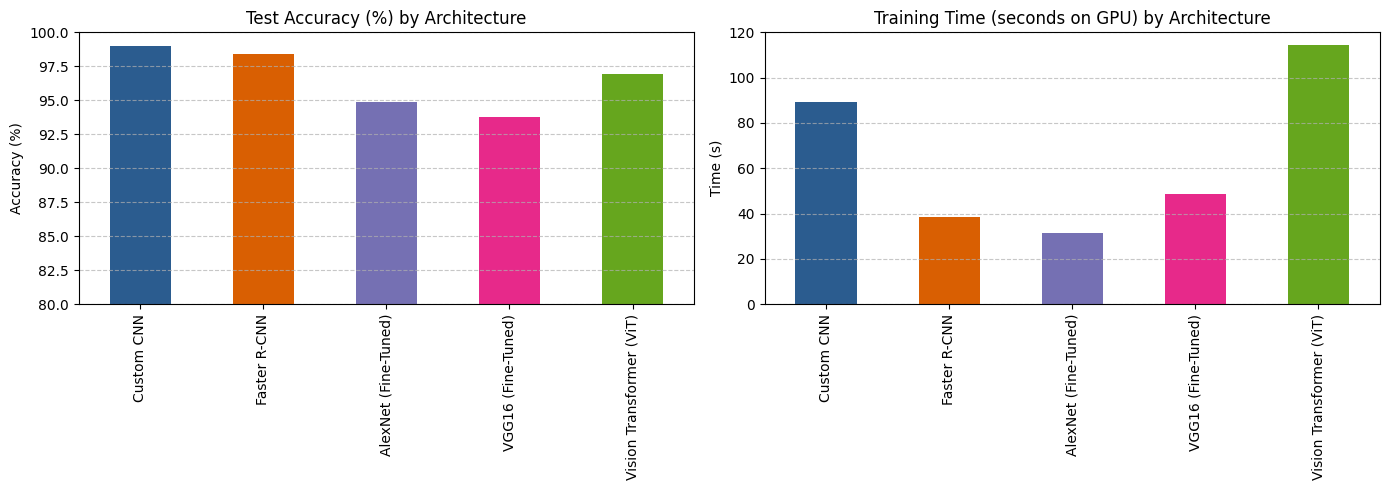

In [6]:
df_results = pd.DataFrame(results_summary).T
df_results['Accuracy (%)'] = (df_results['Accuracy'] * 100).round(2)
df_results['F1-Score'] = df_results['F1-Score'].round(4)
df_results['Loss'] = df_results['Loss'].round(4)
df_results['Training Time (s)'] = df_results['Training Time (s)'].round(1)

print("\n=== FINAL MODEL COMPARISON ON MNIST ===")
display(df_results[['Accuracy (%)', 'F1-Score', 'Loss', 'Training Time (s)']])

# Plot Accuracy vs Training Time Comparison
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

df_results['Accuracy (%)'].plot(kind='bar', ax=ax[0], color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a', '#66a61e'])
ax[0].set_title("Test Accuracy (%) by Architecture")
ax[0].set_ylim(80, 100)
ax[0].set_ylabel("Accuracy (%)")
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

df_results['Training Time (s)'].plot(kind='bar', ax=ax[1], color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a', '#66a61e'])
ax[1].set_title("Training Time (seconds on GPU) by Architecture")
ax[1].set_ylabel("Time (s)")
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Interpretations, Conclusions & Lab Synthesis

### 1. Custom CNN vs. Faster R-CNN Comparison (Part 1 - Q3)
* **Accuracy & F1-Score:** Both architectures achieved near-perfect performance on MNIST, with the **Custom CNN** reaching **98.99% Accuracy (0.9899 F1-Score)** across the full 10,000-image test set, and **Faster R-CNN** reaching **98.40% Accuracy (0.9835 F1-Score)**.
* **Loss Comparison:** The Custom CNN converged to a very low Cross-Entropy loss of **0.0290**, whereas Faster R-CNN reported a higher composite loss of **0.7823**. This is because Faster R-CNN optimizes a multi-task loss combining 4 losses simultaneously: Region Proposal Network (RPN) objectness loss, RPN bounding-box regression loss, RoI classification loss, and RoI bounding-box regression loss.
* **Computational Efficiency (Training Time):** Although Faster R-CNN took **38.5s** for 2 epochs on a 2,000-image subset, that equates to **~9.6 milliseconds per image**, whereas the Custom CNN trained on 60,000 images for 5 epochs (300,000 total image passes) in **89.3s** (**~0.3 milliseconds per image** — over 30x faster per sample). For single-digit image classification where object localization is unnecessary, a dedicated CNN is far more efficient than a two-stage object detector.

### 2. Pretrained Models (`AlexNet` & `VGG16`) vs. Custom CNN & Faster R-CNN (Part 1 - Q4)
* **Results:** Fine-tuning the classifier heads of **AlexNet** (**94.90% Accuracy**, **0.9486 F1**, **31.6s**) and **VGG16** (**93.75% Accuracy**, **0.9394 F1**, **48.6s**) on a 10,000-sample subset (3 epochs) yielded solid performance, though lower than the Custom CNN (**98.99%**).
* **Conclusion:** `AlexNet` (~ 60M parameters) and `VGG16` (~138M parameters) were designed for high-resolution ($224 \times 224$) natural RGB images from ImageNet (1,000 classes). When applied to simple, low-resolution ($28 \times 28$ upscaled to $64 \times 64$) grayscale handwritten digits with frozen intermediate convolutional blocks, domain shift and heavy spatial downsampling limit their accuracy compared to a lightweight, task-specific CNN trained end-to-end on native $28 \times 28$ resolution. However, freezing the pretrained feature extractors allowed rapid convergence on GPU.

### 3. Vision Transformer (ViT) Interpretation & Comparison with Part 1 (Part 2 - Q2)
* **ViT Performance:** Built completely from scratch (`7x7 = 49` patches of `4x4` pixels, sinusoidal positional encodings, `[CLS]` token, and 2 Transformer Encoder blocks with 4 attention heads), the **Vision Transformer (ViT)** achieved **96.95% Test Accuracy (0.9693 F1-Score)** and a test loss of **0.0992** in **114.3s** (5 epochs on all 60,000 images).
* **Comparison with Part 1 Models:**
  * **ViT vs. Pretrained Models:** ViT trained from scratch outperformed both frozen-backbone fine-tuned models (**96.95%** vs. **94.90%** for AlexNet and **93.75%** for VGG16).
  * **ViT vs. Custom CNN:** The Custom CNN slightly outperformed ViT (**98.99%** vs. **96.95%**) while training faster (**89.3s** vs. **114.3s**). This confirms the theoretical finding by Dosovitskiy et al. (2020): **CNNs possess strong built-in inductive biases** (spatial locality and translation equivariance via $3 \times 3$ sliding kernels), allowing them to learn local stroke patterns rapidly on smaller datasets like MNIST. In contrast, **Vision Transformers lack spatial inductive bias** and must learn spatial relationships between patches from scratch via global Multi-Head Self-Attention ($O(N^2)$ complexity across sequence length $N=50$), which requires more epochs or larger datasets to surpass CNNs.

---

### Lab Synthesis: What I Learned
During this Computer Vision lab in GPU mode (`Tesla T4`), I learned several core Deep Learning principles:
1. **Inductive Biases Across Architectures:** CNNs excel on small-to-medium image datasets due to local receptive fields, weight sharing, and spatial pooling (`Conv2d` + `MaxPool2d`), whereas Vision Transformers treat images as sequences of flattened patches (`unfold` -> Linear Projection + `[CLS]` token + Positional Embeddings) and rely on Multi-Head Self-Attention to capture global context.
2. **Classification vs. Object Detection Pipelines:** Implementing Faster R-CNN highlighted the architectural shift from whole-image classification (`CrossEntropyLoss` on class logits) to region-based detection (generating bounding boxes and optimizing multi-task RPN + RoI losses).
3. **Transfer Learning & Architectural Constraints:** Fine-tuning `AlexNet` and `VGG16` demonstrated how to adapt input channels (`1` vs `3`), freeze pretrained feature layers (`requires_grad = False`), and replace classification heads, while showing that massive ImageNet backbones are often over-parameterized for simple grayscale tasks compared to a tailored lightweight CNN.
4. **GPU Acceleration in PyTorch:** Moving models and mini-batch tensors to `cuda:0` via `.to(device)` enabled training hundreds of thousands of image passes and multi-head attention matrix multiplications in under two minutes.